In [17]:
%pip install "nbformat>=4.2.0"


   ----------- ---------------------------- 2/7 [attrs]
   ----------- ---------------------------- 2/7 [attrs]
   ----------------- ---------------------- 3/7 [referencing]
   ---------------------------- ----------- 5/7 [jsonschema]
   ---------------------------- ----------- 5/7 [jsonschema]
   ---------------------------- ----------- 5/7 [jsonschema]
   ---------------------------------- ----- 6/7 [nbformat]
   ---------------------------------- ----- 6/7 [nbformat]
   ---------------------------------------- 7/7 [nbformat]

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [2]:
import nbformat
import plotly.io as pio
import plotly.graph_objects as go

print("nbformat 版本：", nbformat.__version__)

# 在 Notebook 内显示，兼容常见 Notebook 界面
pio.renderers.default = "plotly_mimetype+notebook"

nbformat 版本： 5.11.1


# Main notebook for battery state estimation

In [4]:
import numpy as np
import pandas as pd
import scipy.io
import math
import os
import ntpath
import sys
import logging
import time
import sys

from importlib import reload
import plotly.graph_objects as go
import matplotlib.pyplot as plt
# import tikzplotlib
from matplotlib.font_manager import FontProperties

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from keras.models import Sequential
from keras.layers.core import Dense, Dropout, Activation
from keras.optimizers import SGD, Adam
from keras.utils import np_utils
from keras.layers import LSTM, Embedding, RepeatVector, TimeDistributed, Masking
from keras.callbacks import EarlyStopping, ModelCheckpoint, LambdaCallback


from pathlib import Path
import sys

# 当前工作目录是 results/lg，向上两层就是项目根目录
project_root = Path.cwd().resolve().parents[1]

data_path = project_root.as_posix() + "/"
sys.path.insert(0, str(project_root))

# lg_dataset.py 位于项目根目录，直接导入
from lg_dataset import LgData

print("项目根目录：", project_root)
print("LgData 导入成功！")

项目根目录： C:\Users\MSI-NB\研究生\Deep Lstm\battery-state-estimation
LgData 导入成功！


In [5]:
from pathlib import Path

root = Path.cwd().resolve().parents[1]
print("检查的项目根目录：", root)

print("\n项目根目录中的内容：")
for item in sorted(root.iterdir()):
    label = "文件夹" if item.is_dir() else "文件"
    print(f"[{label}] {item.name}")

folder = root / "data_processing"

print("\ndata_processing 中的内容：")
if folder.is_dir():
    for item in sorted(folder.iterdir()):
        print(item.name)
else:
    print("项目根目录下没有 data_processing 文件夹")

检查的项目根目录： C:\Users\MSI-NB\研究生\Deep Lstm\battery-state-estimation

项目根目录中的内容：
[文件夹] .ipynb_checkpoints
[文件夹] __pycache__
[文件夹] data
[文件] data_description.md
[文件夹] data_processing
[文件] environment.yml
[文件夹] experiments
[文件] lg_dataset.py
[文件] lstm_soc_percentage_lg_positive_temp_500_steps_drive_cycle_test.ipynb
[文件夹] results

data_processing 中的内容：
.ipynb_checkpoints
__pycache__
model_data_handler.py
unibo_powertools_data.py


### Config logging

In [6]:
reload(logging)
logging.basicConfig(format='%(asctime)s [%(levelname)s]: %(message)s', level=logging.DEBUG, datefmt='%Y/%m/%d %H:%M:%S')

# Load Data

In [7]:
train_names = [
    '0degC/589_Mixed1',
    '0degC/589_Mixed2',
    '0degC/590_Mixed4',
    '0degC/590_Mixed5',
    '0degC/590_Mixed6',
    '0degC/590_Mixed8',

    '10degC/567_Mixed1',
    '10degC/567_Mixed2',
    '10degC/571_Mixed4',
    '10degC/571_Mixed5',
    '10degC/571_Mixed6',
    '10degC/571_Mixed8',
    
    '25degC/551_Mixed1', 
    '25degC/551_Mixed2', 
    #'25degC/552_Mixed3',
    '25degC/552_Mixed4', 
    '25degC/552_Mixed5', 
    '25degC/552_Mixed6', 
    '25degC/552_Mixed8',   
    ]
test_names = [
    '0degC/589_LA92',
    '0degC/589_UDDS',
    '0degC/589_US06',
    #'0degC/589_HWFET',
    '0degC/590_Mixed7',    
        
    '10degC/582_LA92',
    '10degC/576_UDDS',
    '10degC/567_US06',
    #'10degC/576_HWFET',
    '10degC/571_Mixed7',

    '25degC/551_LA92', 
    '25degC/551_UDDS', 
    '25degC/551_US06',
    #'25degC/551_HWFET',
    '25degC/552_Mixed7', 
    ]

steps = 300

lg_data = LgData(data_path)
cycles = lg_data.get_discharge_whole_cycle(train_names, test_names, output_capacity=False, scale_test=True, output_time=True)
train_x, train_y, test_x, test_y = lg_data.get_discharge_multiple_step(cycles, steps)

train_y = lg_data.keep_only_y_end(train_y, steps)
test_y = lg_data.keep_only_y_end(test_y, steps)

2026/10/26 10:11:40 [INFO]: There is a NaN in cycle 10degC/582_LA92, removing row
2026/10/26 10:12:23 [INFO]: Train x: (4068, 300, 3), train y: (4068, 300, 2) | Test x: (3218, 300, 3), test y: (3218, 300, 2)


In [8]:
# Model definition

#opt = tf.keras.optimizers.Adam(lr=0.00001)

#model = Sequential()
#model.add(LSTM(256, activation='selu',
#                return_sequences=True,
#                input_shape=(train_x.shape[1], train_x.shape[2])))
#model.add(LSTM(256, activation='selu', return_sequences=False))
#model.add(Dense(256, activation='selu'))
#model.add(Dense(128, activation='selu'))
#model.add(Dense(1, activation='linear'))
#model.summary()

#model.compile(optimizer=opt, loss='huber', metrics=['mse', 'mae', 'mape', tf.keras.metrics.RootMeanSquaredError(name='rmse')

In [9]:
experiment_name = '2026-10-25-20-55-49_lstm_soc_percentage_lg_positive_temp_300_steps_mixed_cycle_test'

history = pd.read_csv(data_path + 'results/trained_model/%s_history.csv' % experiment_name)
model = keras.models.load_model(data_path + 'results/trained_model/%s.h5' % experiment_name)
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm (LSTM)                 (None, 300, 256)          266240    
                                                                 
 lstm_1 (LSTM)               (None, 256)               525312    
                                                                 
 dense (Dense)               (None, 256)               65792     
                                                                 
 dense_1 (Dense)             (None, 128)               32896     
                                                                 
 dense_2 (Dense)             (None, 1)                 129       
                                                                 
Total params: 890,369
Trainable params: 890,369
Non-trainable params: 0
_________________________________________________________________


In [10]:
print(history)

     Unnamed: 0      loss       mse       mae        mape      rmse  val_loss  \
0             0  0.034112  0.068947  0.154860  118.218315  0.262577  0.002353   
1             1  0.001258  0.002515  0.038127   86.659744  0.050150  0.001262   
2             2  0.000957  0.001913  0.033278   70.387253  0.043738  0.000887   
3             3  0.000804  0.001607  0.030649   67.536453  0.040093  0.000750   
4             4  0.000723  0.001446  0.029194   49.731815  0.038022  0.000845   
..          ...       ...       ...       ...         ...       ...       ...   
279         279  0.000179  0.000357  0.014662   20.677092  0.018895  0.000188   
280         280  0.000151  0.000302  0.013463    6.979990  0.017376  0.000136   
281         281  0.000187  0.000374  0.015056   11.557318  0.019339  0.000175   
282         282  0.000157  0.000314  0.013734    7.825677  0.017712  0.000169   
283         283  0.000164  0.000329  0.014130   21.148251  0.018133  0.000138   

      val_mse   val_mae   v

# Test

In [11]:
results = model.evaluate(test_x, test_y[:,:,0])
print(results)

101/101 [==============================] - 26s 247ms/step - loss: 2.0705e-04 - mse: 4.1411e-04 - mae: 0.0153 - mape: 16.6706 - rmse: 0.0203
[0.0002070540504064411, 0.0004141081008128822, 0.015347233973443508, 16.670618057250977, 0.020349645987153053]


# Data Visualization

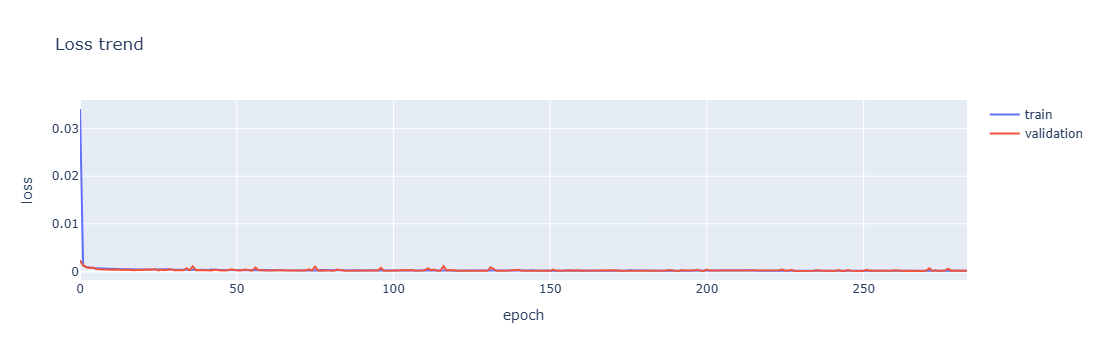

In [12]:
fig = go.Figure()
fig.add_trace(go.Scatter(y=history['loss'],
                    mode='lines', name='train'))
fig.add_trace(go.Scatter(y=history['val_loss'],
                    mode='lines', name='validation'))
fig.update_layout(title='Loss trend',
                  xaxis_title='epoch',
                  yaxis_title='loss')
fig.show()

In [13]:
train_predictions = model.predict(train_x)

128/128 [==============================] - 31s 241ms/step


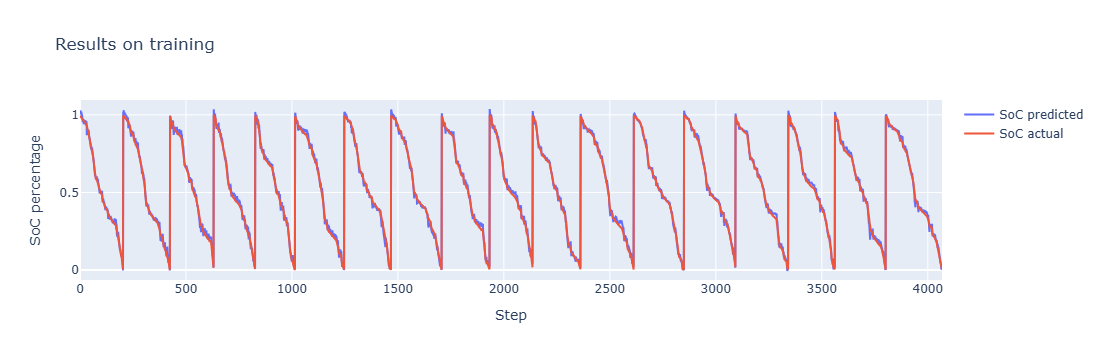

In [14]:
cycle_num = 0
steps_num = 8000
step_index = np.arange(cycle_num*steps_num, (cycle_num+1)*steps_num)

fig = go.Figure()
fig.add_trace(go.Scatter(x=step_index, y=train_predictions.flatten()[cycle_num*steps_num:(cycle_num+1)*steps_num],
                    mode='lines', name='SoC predicted'))
fig.add_trace(go.Scatter(x=step_index, y=train_y[:,:,0].flatten()[cycle_num*steps_num:(cycle_num+1)*steps_num],
                    mode='lines', name='SoC actual'))
fig.update_layout(title='Results on training',
                  xaxis_title='Step',
                  yaxis_title='SoC percentage')
fig.show()

# Testing

Test model performance on every temperature dataset

In [19]:
font = FontProperties()
font.set_family('serif')
font.set_name('DejaVu Serif')

In [20]:
def get_test_data(test_names):
    lg_data = LgData(data_path)
    cycles = lg_data.get_discharge_whole_cycle(train_names, test_names, output_capacity=False, scale_test=True, output_time=True)
    _, _, test_x, test_y = lg_data.get_discharge_multiple_step(cycles, steps)
    test_y = lg_data.keep_only_y_end(test_y, steps)    
    return test_x, test_y

def plot_test_performance(test_x, test_y):
    test_predictions = model.predict(test_x)
    
    fig = go.Figure()
    fig.add_trace(go.Scatter(x=test_y[:,:,1].flatten(), y=test_predictions.flatten(),
                        mode='lines', name='SoC predicted'))
    fig.add_trace(go.Scatter(x=test_y[:,:,1].flatten(), y=test_y[:,:,0].flatten(),
                        mode='lines', name='SoC actual'))
    fig.update_layout(title='Results on testing',
                      xaxis_title='Time(s)',
                      yaxis_title='SoC percentage')
    fig.show()
    
def gen_chart(test_name, test_x, test_y):
    test_predictions = model.predict(test_x)
    
    f = plt.figure(figsize=(5,2))
    plt.plot(test_y[:,:,1].flatten(), test_y[:,:,0].flatten(), label='Actual', color='black')
    plt.plot(test_y[:,:,1].flatten(), test_predictions.flatten(), label='Estimated', linestyle='--', color='red')
    plt.xlabel('Time(s)', fontproperties=font)
    plt.ylabel('SOC', fontproperties=font)
    plt.legend()
    plt.show()
    f.savefig('./lstm_soc_percentage_lg_positive_temp_300_steps_mixed_cycle_test_%s.pdf' % test_name, bbox_inches='tight')
    
def show_result(cycle, name):
    test_x, test_y = get_test_data([cycle])

    print(model.evaluate(test_x, test_y[:,:,0]))
    plot_test_performance(test_x, test_y)

    test_x, test_y = get_test_data([cycle])
    gen_chart(name, test_x, test_y)

## 0C

2021/01/14 18:44:57 [INFO]: Train x: (4068, 300, 3), train y: (4068, 300, 2) | Test x: (976, 300, 3), test y: (976, 300, 2)


31/31 [==============================] - 3s 87ms/step - loss: 2.5701e-04 - mean_squared_error: 5.1402e-04 - mean_absolute_error: 0.0169 - mean_absolute_percentage_error: 13.0176 - rmse: 0.0227
[0.0002570112410467118, 0.0005140224820934236, 0.01689271256327629, 13.017587661743164, 0.02267206460237503]


2021/01/14 18:45:21 [INFO]: Train x: (4068, 300, 3), train y: (4068, 300, 2) | Test x: (251, 300, 3), test y: (251, 300, 2)


8/8 [==============================] - 1s 80ms/step - loss: 1.3673e-04 - mean_squared_error: 2.7346e-04 - mean_absolute_error: 0.0125 - mean_absolute_percentage_error: 7.0246 - rmse: 0.0165
[0.00013672975182998925, 0.0002734595036599785, 0.012536490336060524, 7.0245513916015625, 0.016536610201001167]


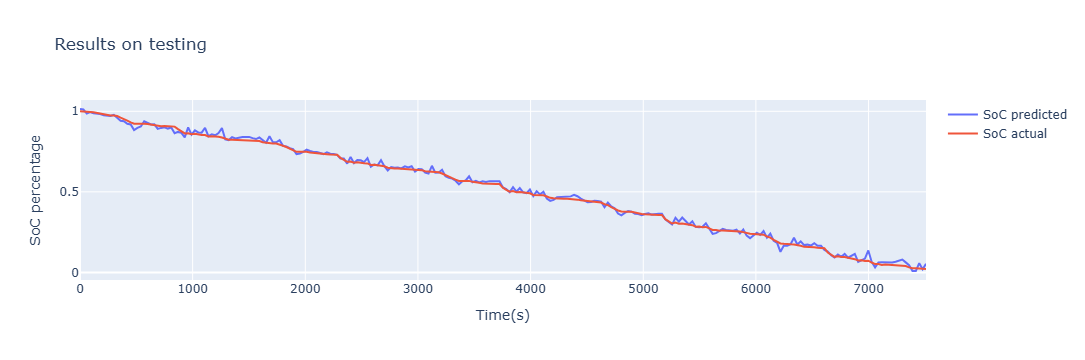

2021/01/14 18:45:42 [INFO]: Train x: (4068, 300, 3), train y: (4068, 300, 2) | Test x: (251, 300, 3), test y: (251, 300, 2)


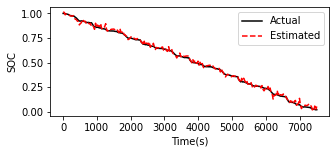

2021/01/14 18:45:43 [DEBUG]: Assigning font /b'F1' = '/usr/local/lib/python3.6/dist-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf'
2021/01/14 18:45:43 [DEBUG]: Embedding font /usr/local/lib/python3.6/dist-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf.
2021/01/14 18:45:43 [DEBUG]: Writing TrueType font.
2021/01/14 18:46:04 [INFO]: Train x: (4068, 300, 3), train y: (4068, 300, 2) | Test x: (448, 300, 3), test y: (448, 300, 2)


14/14 [==============================] - 1s 84ms/step - loss: 2.1504e-04 - mean_squared_error: 4.3009e-04 - mean_absolute_error: 0.0166 - mean_absolute_percentage_error: 18.7413 - rmse: 0.0207
[0.00021504273172467947, 0.00043008546344935894, 0.016571534797549248, 18.741254806518555, 0.020738501101732254]


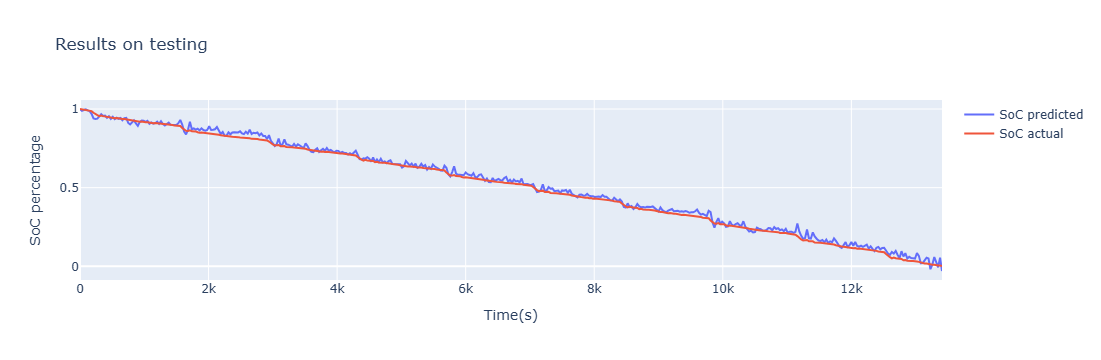

2021/01/14 18:46:27 [INFO]: Train x: (4068, 300, 3), train y: (4068, 300, 2) | Test x: (448, 300, 3), test y: (448, 300, 2)


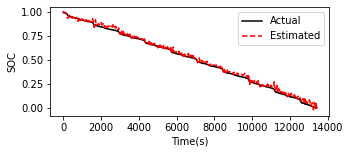

2021/01/14 18:46:29 [DEBUG]: Assigning font /b'F1' = '/usr/local/lib/python3.6/dist-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf'
2021/01/14 18:46:29 [DEBUG]: Embedding font /usr/local/lib/python3.6/dist-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf.
2021/01/14 18:46:29 [DEBUG]: Writing TrueType font.
2021/01/14 18:46:49 [INFO]: Train x: (4068, 300, 3), train y: (4068, 300, 2) | Test x: (92, 300, 3), test y: (92, 300, 2)


3/3 [==============================] - 0s 64ms/step - loss: 6.0865e-04 - mean_squared_error: 0.0012 - mean_absolute_error: 0.0257 - mean_absolute_percentage_error: 9.6733 - rmse: 0.0349
[0.0006086454959586263, 0.0012172909919172525, 0.025683190673589706, 9.673285484313965, 0.03488969802856445]


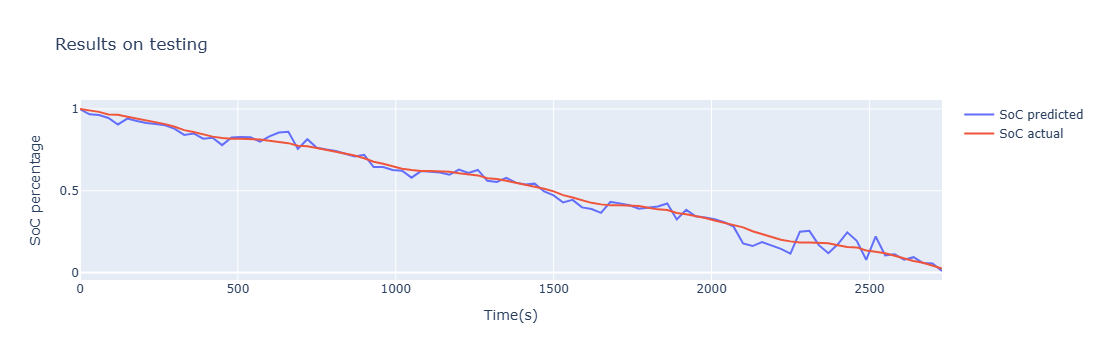

2021/01/14 18:47:09 [INFO]: Train x: (4068, 300, 3), train y: (4068, 300, 2) | Test x: (92, 300, 3), test y: (92, 300, 2)


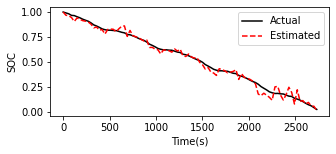

2021/01/14 18:47:10 [DEBUG]: Assigning font /b'F1' = '/usr/local/lib/python3.6/dist-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf'
2021/01/14 18:47:10 [DEBUG]: Embedding font /usr/local/lib/python3.6/dist-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf.
2021/01/14 18:47:10 [DEBUG]: Writing TrueType font.
2021/01/14 18:47:30 [INFO]: Train x: (4068, 300, 3), train y: (4068, 300, 2) | Test x: (185, 300, 3), test y: (185, 300, 2)


6/6 [==============================] - 0s 74ms/step - loss: 3.4697e-04 - mean_squared_error: 6.9394e-04 - mean_absolute_error: 0.0192 - mean_absolute_percentage_error: 8.9512 - rmse: 0.0263
[0.00034696879447437823, 0.0006939375889487565, 0.019209323450922966, 8.951239585876465, 0.026342695578932762]


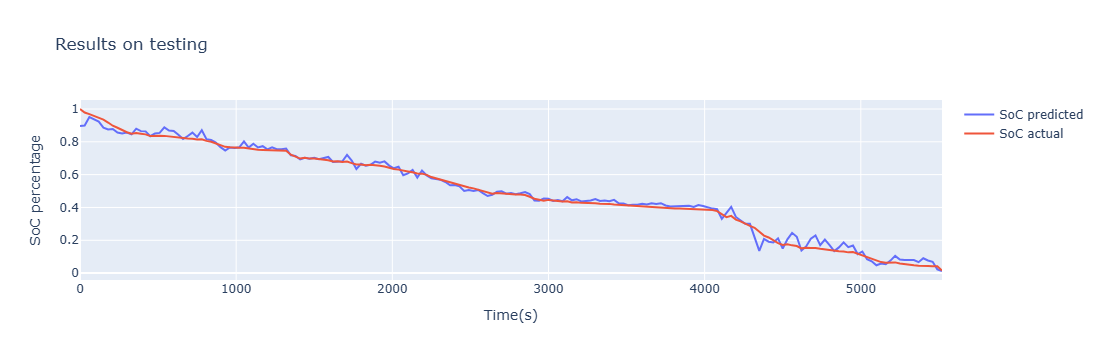

2021/01/14 18:47:52 [INFO]: Train x: (4068, 300, 3), train y: (4068, 300, 2) | Test x: (185, 300, 3), test y: (185, 300, 2)


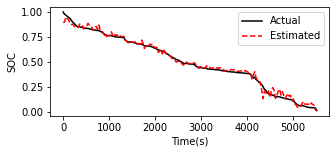

2021/01/14 18:47:52 [DEBUG]: Assigning font /b'F1' = '/usr/local/lib/python3.6/dist-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf'
2021/01/14 18:47:52 [DEBUG]: Embedding font /usr/local/lib/python3.6/dist-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf.
2021/01/14 18:47:52 [DEBUG]: Writing TrueType font.


In [20]:
test_x, test_y = get_test_data(['0degC/589_LA92', 
                                '0degC/589_UDDS', 
                                '0degC/589_US06', 
                                #'0degC/589_HWFET', 
                                '0degC/590_Mixed7'])
print(model.evaluate(test_x, test_y[:,:,0]))

show_result('0degC/589_LA92', '0degC_589_LA92')
show_result('0degC/589_UDDS', '0degC_589_UDDS')
show_result('0degC/589_US06', '0degC_589_US06')
#show_result('0degC/589_HWFET', '0degC_589_HWFET')
show_result('0degC/590_Mixed7', '0degC_590_Mixed7')

## 10C

2021/01/14 18:48:00 [INFO]: There is a NaN in cycle 10degC/582_LA92, removing row
2021/01/14 18:48:15 [INFO]: Train x: (4068, 300, 3), train y: (4068, 300, 2) | Test x: (1078, 300, 3), test y: (1078, 300, 2)


34/34 [==============================] - 3s 85ms/step - loss: 2.2577e-04 - mean_squared_error: 4.5153e-04 - mean_absolute_error: 0.0161 - mean_absolute_percentage_error: 8.6160 - rmse: 0.0212
[0.00022576560149900615, 0.0004515312029980123, 0.01609964296221733, 8.615970611572266, 0.02124926447868347]


2021/01/14 18:48:38 [INFO]: Train x: (4068, 300, 3), train y: (4068, 300, 2) | Test x: (476, 300, 3), test y: (476, 300, 2)


15/15 [==============================] - 1s 84ms/step - loss: 1.4189e-04 - mean_squared_error: 2.8378e-04 - mean_absolute_error: 0.0132 - mean_absolute_percentage_error: 8.4400 - rmse: 0.0168
[0.00014189239300321788, 0.00028378478600643575, 0.013175217434763908, 8.439971923828125, 0.016845913603901863]


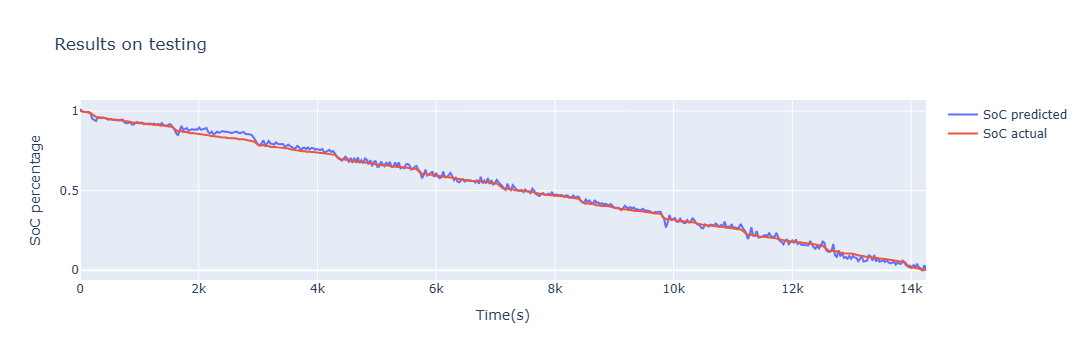

2021/01/14 18:49:02 [INFO]: Train x: (4068, 300, 3), train y: (4068, 300, 2) | Test x: (476, 300, 3), test y: (476, 300, 2)


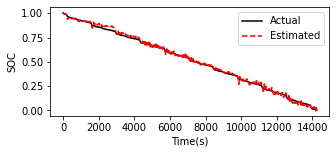

2021/01/14 18:49:04 [DEBUG]: Assigning font /b'F1' = '/usr/local/lib/python3.6/dist-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf'
2021/01/14 18:49:04 [DEBUG]: Embedding font /usr/local/lib/python3.6/dist-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf.
2021/01/14 18:49:04 [DEBUG]: Writing TrueType font.
2021/01/14 18:49:24 [INFO]: Train x: (4068, 300, 3), train y: (4068, 300, 2) | Test x: (109, 300, 3), test y: (109, 300, 2)


4/4 [==============================] - 0s 65ms/step - loss: 7.1325e-04 - mean_squared_error: 0.0014 - mean_absolute_error: 0.0312 - mean_absolute_percentage_error: 11.0588 - rmse: 0.0378
[0.0007132496102713048, 0.0014264992205426097, 0.031201446428894997, 11.05876636505127, 0.037769023329019547]


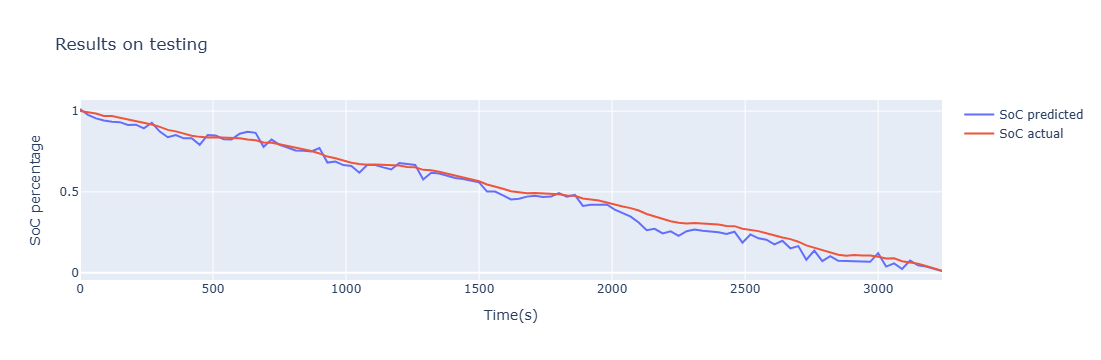

2021/01/14 18:49:45 [INFO]: Train x: (4068, 300, 3), train y: (4068, 300, 2) | Test x: (109, 300, 3), test y: (109, 300, 2)


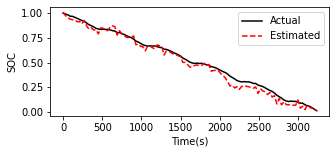

2021/01/14 18:49:46 [DEBUG]: Assigning font /b'F1' = '/usr/local/lib/python3.6/dist-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf'
2021/01/14 18:49:46 [DEBUG]: Embedding font /usr/local/lib/python3.6/dist-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf.
2021/01/14 18:49:46 [DEBUG]: Writing TrueType font.
2021/01/14 18:49:53 [INFO]: There is a NaN in cycle 10degC/582_LA92, removing row
2021/01/14 18:50:06 [INFO]: Train x: (4068, 300, 3), train y: (4068, 300, 2) | Test x: (282, 300, 3), test y: (282, 300, 2)


9/9 [==============================] - 1s 81ms/step - loss: 1.6602e-04 - mean_squared_error: 3.3204e-04 - mean_absolute_error: 0.0146 - mean_absolute_percentage_error: 7.5741 - rmse: 0.0182
[0.00016601852257736027, 0.00033203704515472054, 0.01464369148015976, 7.574100017547607, 0.018221883103251457]


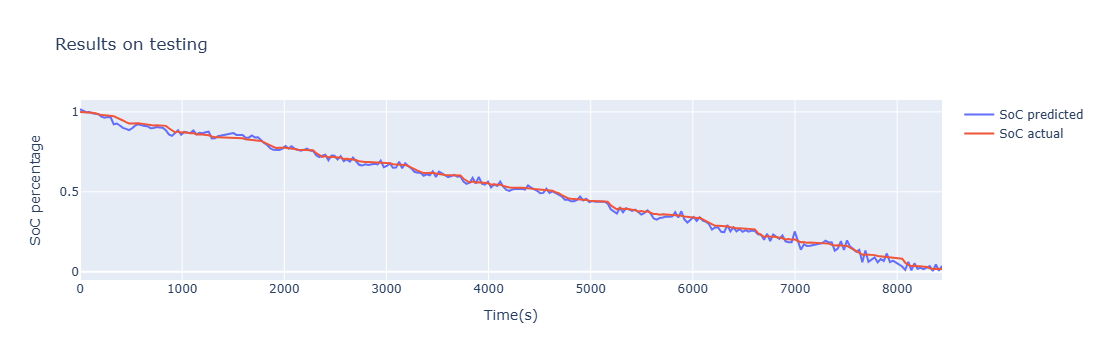

2021/01/14 18:50:15 [INFO]: There is a NaN in cycle 10degC/582_LA92, removing row
2021/01/14 18:50:28 [INFO]: Train x: (4068, 300, 3), train y: (4068, 300, 2) | Test x: (282, 300, 3), test y: (282, 300, 2)


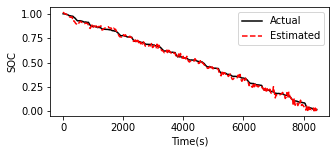

2021/01/14 18:50:29 [DEBUG]: Assigning font /b'F1' = '/usr/local/lib/python3.6/dist-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf'
2021/01/14 18:50:29 [DEBUG]: Embedding font /usr/local/lib/python3.6/dist-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf.
2021/01/14 18:50:29 [DEBUG]: Writing TrueType font.
2021/01/14 18:50:50 [INFO]: Train x: (4068, 300, 3), train y: (4068, 300, 2) | Test x: (211, 300, 3), test y: (211, 300, 2)


7/7 [==============================] - 1s 77ms/step - loss: 2.4300e-04 - mean_squared_error: 4.8600e-04 - mean_absolute_error: 0.0168 - mean_absolute_percentage_error: 9.1435 - rmse: 0.0220
[0.0002430007152725011, 0.0004860014305450022, 0.01684139296412468, 9.143545150756836, 0.02204544097185135]


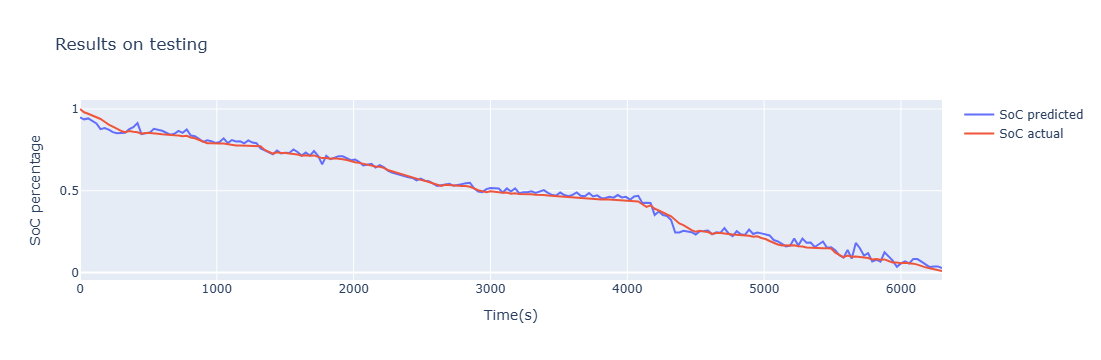

2021/01/14 18:51:11 [INFO]: Train x: (4068, 300, 3), train y: (4068, 300, 2) | Test x: (211, 300, 3), test y: (211, 300, 2)


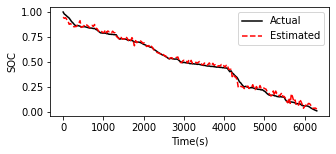

2021/01/14 18:51:12 [DEBUG]: Assigning font /b'F1' = '/usr/local/lib/python3.6/dist-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf'
2021/01/14 18:51:12 [DEBUG]: Embedding font /usr/local/lib/python3.6/dist-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf.
2021/01/14 18:51:12 [DEBUG]: Writing TrueType font.


In [21]:
test_x, test_y = get_test_data(['10degC/576_UDDS', 
                                '10degC/567_US06', 
                                '10degC/582_LA92',
                                #'10degC/576_HWFET', 
                                '10degC/571_Mixed7'])
print(model.evaluate(test_x, test_y[:,:,0]))

show_result('10degC/576_UDDS', '10degC_576_UDDS')
show_result('10degC/567_US06', '10degC_567_US06')
show_result('10degC/582_LA92', '10degC_582_LA92')
#show_result('10degC/576_HWFET', '10degC_576_HWFET')
show_result('10degC/571_Mixed7', '10degC_571_Mixed7')

## 25C

2026/10/26 10:22:26 [INFO]: Train x: (4068, 300, 3), train y: (4068, 300, 2) | Test x: (1164, 300, 3), test y: (1164, 300, 2)


37/37 [==============================] - 10s 255ms/step - loss: 1.5363e-04 - mse: 3.0726e-04 - mae: 0.0136 - mape: 10.5079 - rmse: 0.0175
[0.00015363114653155208, 0.00030726229306310415, 0.013605340383946896, 10.50787353515625, 0.017528899013996124]


2026/10/26 10:23:13 [INFO]: Train x: (4068, 300, 3), train y: (4068, 300, 2) | Test x: (315, 300, 3), test y: (315, 300, 2)


10/10 [==============================] - 3s 260ms/step - loss: 1.1271e-04 - mse: 2.2541e-04 - mae: 0.0123 - mape: 5.8334 - rmse: 0.0150
[0.00011270694085396826, 0.00022541388170793653, 0.01229284331202507, 5.83336067199707, 0.015013789758086205]
10/10 [==============================] - 3s 286ms/step


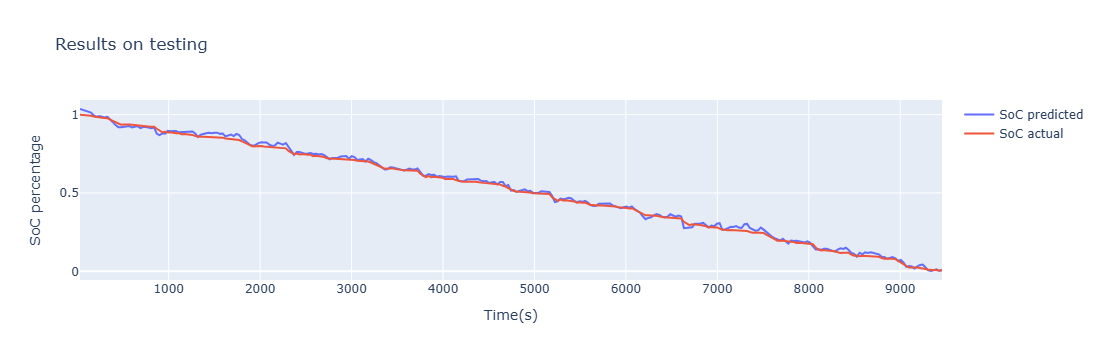

2026/10/26 10:23:52 [INFO]: Train x: (4068, 300, 3), train y: (4068, 300, 2) | Test x: (315, 300, 3), test y: (315, 300, 2)


10/10 [==============================] - 3s 300ms/step


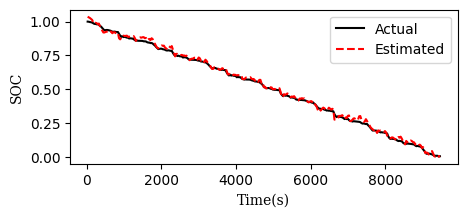

2026/10/26 10:23:56 [DEBUG]: Assigning font /F1 = 'C:\\Users\\MSI-NB\\.conda\\envs\\gpu\\Lib\\site-packages\\matplotlib\\mpl-data\\fonts\\ttf\\DejaVuSans.ttf'
2026/10/26 10:23:56 [DEBUG]: Assigning font /F2 = 'C:\\Users\\MSI-NB\\.conda\\envs\\gpu\\Lib\\site-packages\\matplotlib\\mpl-data\\fonts\\ttf\\DejaVuSerif.ttf'
2026/10/26 10:23:56 [DEBUG]: Embedding font C:\Users\MSI-NB\.conda\envs\gpu\Lib\site-packages\matplotlib\mpl-data\fonts\ttf\DejaVuSans.ttf.
2026/10/26 10:23:56 [DEBUG]: Writing TrueType font.
2026/10/26 10:23:56 [DEBUG]: Embedding font C:\Users\MSI-NB\.conda\envs\gpu\Lib\site-packages\matplotlib\mpl-data\fonts\ttf\DejaVuSerif.ttf.
2026/10/26 10:23:56 [DEBUG]: Writing TrueType font.
2026/10/26 10:24:30 [INFO]: Train x: (4068, 300, 3), train y: (4068, 300, 2) | Test x: (512, 300, 3), test y: (512, 300, 2)


16/16 [==============================] - 6s 315ms/step - loss: 1.0274e-04 - mse: 2.0549e-04 - mae: 0.0117 - mape: 14.4437 - rmse: 0.0143
[0.00010274490341544151, 0.00020548980683088303, 0.011670542880892754, 14.443670272827148, 0.014334915205836296]
16/16 [==============================] - 5s 295ms/step


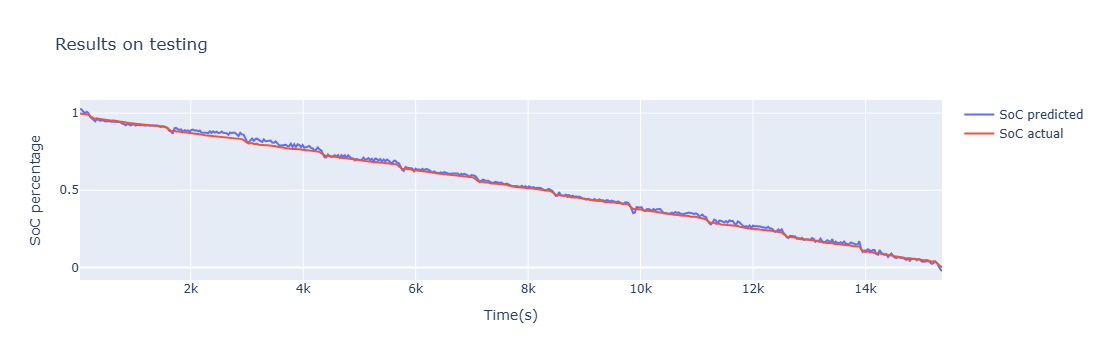

2026/10/26 10:25:14 [INFO]: Train x: (4068, 300, 3), train y: (4068, 300, 2) | Test x: (512, 300, 3), test y: (512, 300, 2)


16/16 [==============================] - 5s 288ms/step


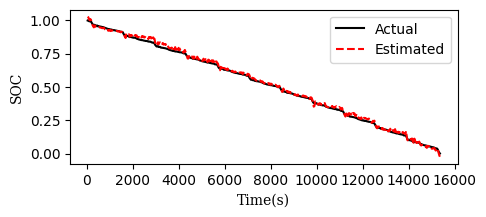

2026/10/26 10:25:19 [DEBUG]: Assigning font /F1 = 'C:\\Users\\MSI-NB\\.conda\\envs\\gpu\\Lib\\site-packages\\matplotlib\\mpl-data\\fonts\\ttf\\DejaVuSans.ttf'
2026/10/26 10:25:19 [DEBUG]: Assigning font /F2 = 'C:\\Users\\MSI-NB\\.conda\\envs\\gpu\\Lib\\site-packages\\matplotlib\\mpl-data\\fonts\\ttf\\DejaVuSerif.ttf'
2026/10/26 10:25:19 [DEBUG]: Embedding font C:\Users\MSI-NB\.conda\envs\gpu\Lib\site-packages\matplotlib\mpl-data\fonts\ttf\DejaVuSans.ttf.
2026/10/26 10:25:19 [DEBUG]: Writing TrueType font.
2026/10/26 10:25:19 [DEBUG]: Embedding font C:\Users\MSI-NB\.conda\envs\gpu\Lib\site-packages\matplotlib\mpl-data\fonts\ttf\DejaVuSerif.ttf.
2026/10/26 10:25:19 [DEBUG]: Writing TrueType font.
2026/10/26 10:25:52 [INFO]: Train x: (4068, 300, 3), train y: (4068, 300, 2) | Test x: (113, 300, 3), test y: (113, 300, 2)


4/4 [==============================] - 2s 292ms/step - loss: 4.3886e-04 - mse: 8.7772e-04 - mae: 0.0228 - mape: 6.4504 - rmse: 0.0296
[0.0004388600355014205, 0.000877720071002841, 0.02275407686829567, 6.450382709503174, 0.02962633967399597]
4/4 [==============================] - 1s 286ms/step


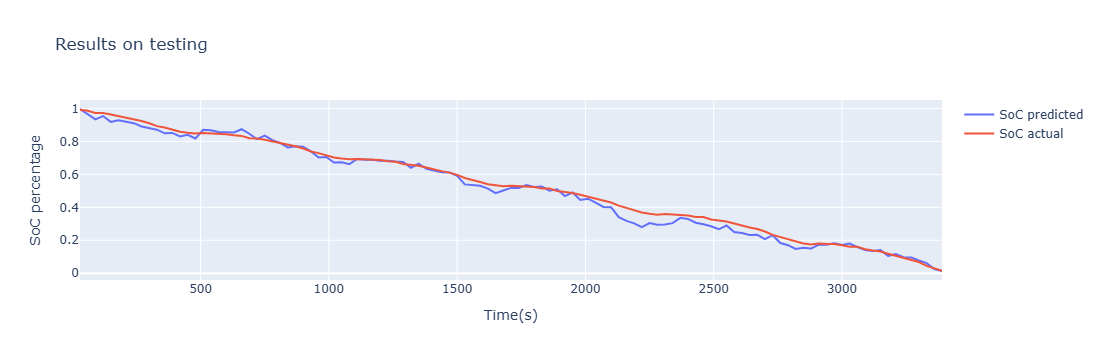

2026/10/26 10:26:28 [INFO]: Train x: (4068, 300, 3), train y: (4068, 300, 2) | Test x: (113, 300, 3), test y: (113, 300, 2)


4/4 [==============================] - 2s 294ms/step


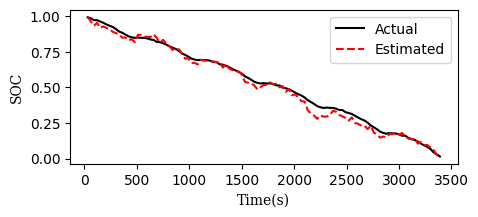

2026/10/26 10:26:30 [DEBUG]: Assigning font /F1 = 'C:\\Users\\MSI-NB\\.conda\\envs\\gpu\\Lib\\site-packages\\matplotlib\\mpl-data\\fonts\\ttf\\DejaVuSans.ttf'
2026/10/26 10:26:30 [DEBUG]: Assigning font /F2 = 'C:\\Users\\MSI-NB\\.conda\\envs\\gpu\\Lib\\site-packages\\matplotlib\\mpl-data\\fonts\\ttf\\DejaVuSerif.ttf'
2026/10/26 10:26:30 [DEBUG]: Embedding font C:\Users\MSI-NB\.conda\envs\gpu\Lib\site-packages\matplotlib\mpl-data\fonts\ttf\DejaVuSans.ttf.
2026/10/26 10:26:30 [DEBUG]: Writing TrueType font.
2026/10/26 10:26:30 [DEBUG]: Embedding font C:\Users\MSI-NB\.conda\envs\gpu\Lib\site-packages\matplotlib\mpl-data\fonts\ttf\DejaVuSerif.ttf.
2026/10/26 10:26:30 [DEBUG]: Writing TrueType font.
2026/10/26 10:27:00 [INFO]: Train x: (4068, 300, 3), train y: (4068, 300, 2) | Test x: (224, 300, 3), test y: (224, 300, 2)


7/7 [==============================] - 3s 289ms/step - loss: 1.8364e-04 - mse: 3.6729e-04 - mae: 0.0153 - mape: 10.1414 - rmse: 0.0192
[0.0001836449227994308, 0.0003672898455988616, 0.015258443541824818, 10.1414213180542, 0.019164806231856346]
7/7 [==============================] - 2s 278ms/step


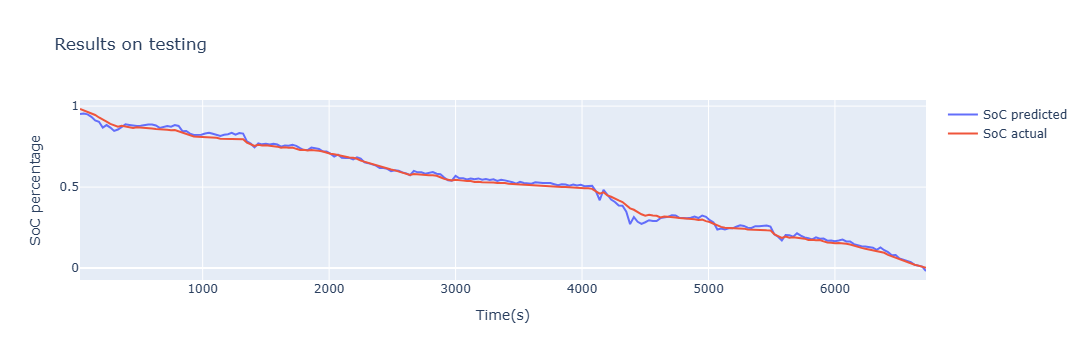

2026/10/26 10:27:40 [INFO]: Train x: (4068, 300, 3), train y: (4068, 300, 2) | Test x: (224, 300, 3), test y: (224, 300, 2)


7/7 [==============================] - 2s 277ms/step


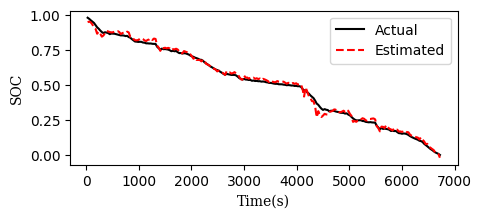

2026/10/26 10:27:43 [DEBUG]: Assigning font /F1 = 'C:\\Users\\MSI-NB\\.conda\\envs\\gpu\\Lib\\site-packages\\matplotlib\\mpl-data\\fonts\\ttf\\DejaVuSans.ttf'
2026/10/26 10:27:43 [DEBUG]: Assigning font /F2 = 'C:\\Users\\MSI-NB\\.conda\\envs\\gpu\\Lib\\site-packages\\matplotlib\\mpl-data\\fonts\\ttf\\DejaVuSerif.ttf'
2026/10/26 10:27:43 [DEBUG]: Embedding font C:\Users\MSI-NB\.conda\envs\gpu\Lib\site-packages\matplotlib\mpl-data\fonts\ttf\DejaVuSans.ttf.
2026/10/26 10:27:43 [DEBUG]: Writing TrueType font.
2026/10/26 10:27:43 [DEBUG]: Embedding font C:\Users\MSI-NB\.conda\envs\gpu\Lib\site-packages\matplotlib\mpl-data\fonts\ttf\DejaVuSerif.ttf.
2026/10/26 10:27:43 [DEBUG]: Writing TrueType font.


In [21]:
test_x, test_y = get_test_data(['25degC/551_LA92', 
                                '25degC/551_UDDS', 
                                '25degC/551_US06', 
                                #'25degC/551_HWFET',
                                '25degC/552_Mixed7'])
print(model.evaluate(test_x, test_y[:,:,0]))

show_result('25degC/551_LA92', '25degC_551_LA92')
show_result('25degC/551_UDDS', '25degC_551_UDDS')
show_result('25degC/551_US06', '25degC_551_US06')
#show_result('25degC/551_HWFET', '25degC_551_HWFET')
show_result('25degC/552_Mixed7', '25degC_552_Mixed7')